In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import splev, splrep

#import color_to_Teff_mc as ct
import photo_spec_teff as ps
import rest2012_joint_mcmc as jm
import rest2012_reddening_mcmc as rm
import rest2012_spectral_type as r12



In [3]:
from LC_utility import convert_Jy2mag
#from pdastro import *

In [76]:
pwd

'/Users/home/Documents/EtaCarEchoes/old_vers1'

In [4]:
ls data/filters

decam/


In [4]:
# Joint Mg+Ca reddening MCMC (rest2012_reddening_mcmc / joint summary)
EBV = 0.909
EBV_ERR = 0.018
RV = 4.8
LINE_TEFF = 5411.0
LINE_TEFF_ERR = 9.0


In [5]:
FILTER_DIR = Path(".data/filters/decam/")

In [6]:
def pickles_gi_calibration(filters, teffs, wave, flux):
    """Intrinsic (g-i)_0 vs Teff for Pickles I (monotonic, cooler = redder)."""
    tgrid = np.linspace(4000.0, 9000.0, 251)
    gi0 = np.empty_like(tgrid)
    for i, t in enumerate(tgrid):
        tmpl = jm.interp_template(float(t), teffs, flux)
        sg, _ = ps.band_signal(wave, tmpl, filters["g"], min_cov=0.7)
        si, _ = ps.band_signal(wave, tmpl, filters["i"], min_cov=0.7)
        gi0[i] = -2.5 * np.log10(sg / si)
    if not np.all(np.diff(gi0) < 0):
        raise RuntimeError("Pickles g-i is not monotonic in Teff")
    return tgrid, gi0



In [35]:
def pickles_gr_calibration(filters, teffs, wave, flux):
    """Intrinsic (g-r)_0 vs Teff for Pickles I (monotonic, cooler = redder)."""
    tgrid = np.linspace(4000.0, 9000.0, 251)
    gr0 = np.empty_like(tgrid)
    for i, t in enumerate(tgrid):
        tmpl = jm.interp_template(float(t), teffs, flux)
        sg, _ = ps.band_signal(wave, tmpl, filters["g"], min_cov=0.7)
        sr, _ = ps.band_signal(wave, tmpl, filters["r"], min_cov=0.7)
        gr0[i] = -2.5 * np.log10(sg / sr)
    if not np.all(np.diff(gi0) < 0):
        raise RuntimeError("Pickles g-i is not monotonic in Teff")
    return tgrid, gr0



In [36]:
def band_extinctions(filters, teffs, wave, flux, ebv: float, rv: float = RV) -> dict[str, float]:
    """A_λ through each DECam band for a 5411 K Pickles I continuum."""
    tmpl = jm.interp_template(LINE_TEFF, teffs, flux)
    out = {}
    for band in "griz":
        s0, _ = ps.band_signal(wave, tmpl, filters[band], min_cov=0.7)
        s1, _ = ps.band_signal(
            wave, tmpl * rm.extinction_factor(wave, ebv, rv=rv), filters[band], min_cov=0.7
        )
        out[band] = float(-2.5 * np.log10(s1 / s0))
    return out


In [37]:
filters = ps.load_filters()

Text(0.5, 0, 'wavelength')

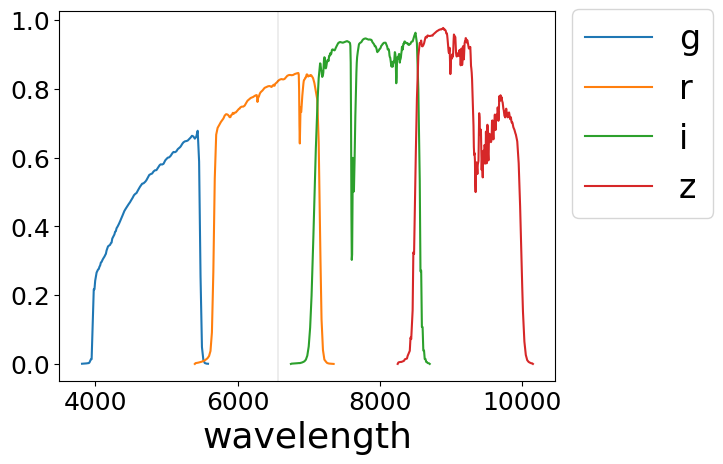

In [38]:
for band in "griz":

    plt.plot(filters[band][0], filters[band][1], label=band)

plt.legend(bbox_to_anchor=(1, 1.05))

plt.axvline(6563, c='k', lw=.1,) # H-alpha line

plt.xlabel('wavelength')

In [39]:

# spectra template 
# https://etc.stsci.edu/etcstatic/users_guide/1_ref_3_pickles.html?utm_source=chatgpt.com#
teffs, _, wave, flux = ps.template_library(filters)



In [40]:
teffs

array([3990.25, 4123.  , 4255.98, 4591.98, 5046.61, 5320.  , 5508.08,
       6095.37, 6637.43, 7691.3 , 8700.  , 9727.47])

In [41]:
flux.shape

(12, 3501)

Text(0.5, 0, '')

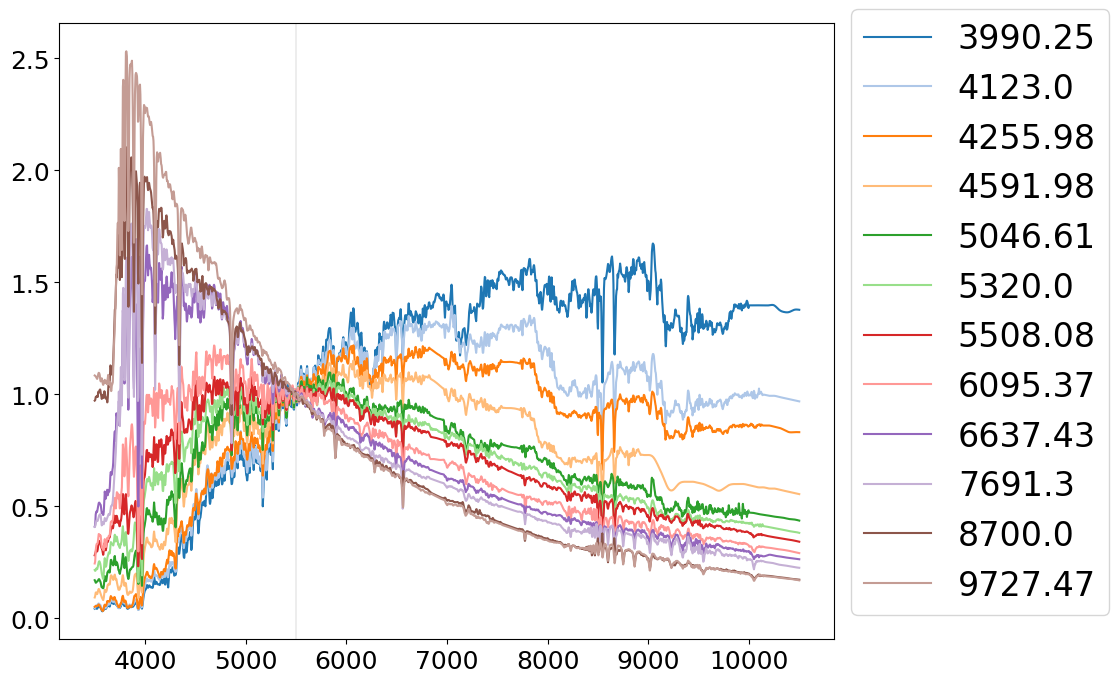

In [42]:
plt.figure(figsize=(10, 8))

for i in range(12):

    plt.plot(wave, flux[i], label=teffs[i], c=plt.cm.tab20(i))

plt.legend(bbox_to_anchor=(1, 1.05))

plt.axvline(5500, c='k', lw=.1,) # normalize 


plt.xlabel('')

In [43]:

# replace np.trapezoid with np.trapz for older numpy version
tgrid, gi0 = pickles_gi_calibration(filters, teffs, wave, flux)


tgrid, gr0 = pickles_gr_calibration(filters, teffs, wave, flux)


In [44]:
tgrid, gi0

(array([4000., 4020., 4040., 4060., 4080., 4100., 4120., 4140., 4160.,
        4180., 4200., 4220., 4240., 4260., 4280., 4300., 4320., 4340.,
        4360., 4380., 4400., 4420., 4440., 4460., 4480., 4500., 4520.,
        4540., 4560., 4580., 4600., 4620., 4640., 4660., 4680., 4700.,
        4720., 4740., 4760., 4780., 4800., 4820., 4840., 4860., 4880.,
        4900., 4920., 4940., 4960., 4980., 5000., 5020., 5040., 5060.,
        5080., 5100., 5120., 5140., 5160., 5180., 5200., 5220., 5240.,
        5260., 5280., 5300., 5320., 5340., 5360., 5380., 5400., 5420.,
        5440., 5460., 5480., 5500., 5520., 5540., 5560., 5580., 5600.,
        5620., 5640., 5660., 5680., 5700., 5720., 5740., 5760., 5780.,
        5800., 5820., 5840., 5860., 5880., 5900., 5920., 5940., 5960.,
        5980., 6000., 6020., 6040., 6060., 6080., 6100., 6120., 6140.,
        6160., 6180., 6200., 6220., 6240., 6260., 6280., 6300., 6320.,
        6340., 6360., 6380., 6400., 6420., 6440., 6460., 6480., 6500.,
      

Text(0, 0.5, 'g-i')

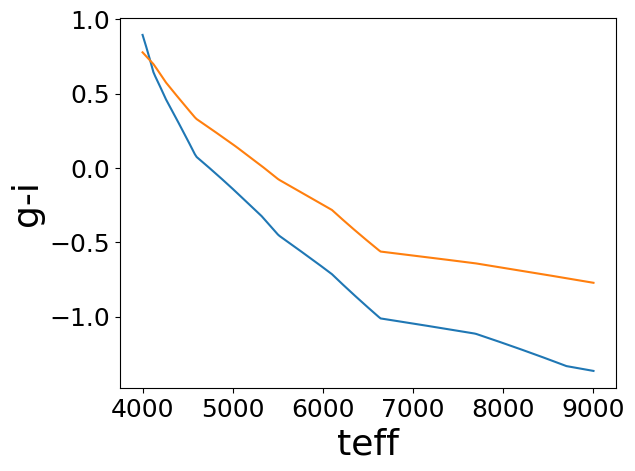

In [45]:
plt.plot(tgrid, gi0)
plt.plot(tgrid, gr0)
#plt.plot(tgrid, ri0)

plt.xlabel('teff')
plt.ylabel('g-i')

In [46]:
def teff_from_gi(gi, tgrid, gi0):
    """Invert (g-i)_0 → Teff. gi0 decreases with Teff."""
    gi = np.asarray(gi, dtype=float)
    return np.interp(gi, gi0[::-1], tgrid[::-1], left=np.nan, right=np.nan)


In [47]:
A = band_extinctions(filters, teffs, wave, flux, EBV, RV)
A_hi = band_extinctions(filters, teffs, wave, flux, EBV + EBV_ERR, RV)
A_lo = band_extinctions(filters, teffs, wave, flux, EBV - EBV_ERR, RV)
e_gi = (A["g"] - A["i"])
de_gi = 0.5 * abs((A_hi["g"] - A_hi["i"]) - (A_lo["g"] - A_lo["i"]))




In [48]:
A

{'g': 4.789150637953749,
 'r': 3.7618838863118143,
 'i': 2.9809967380470215,
 'z': 2.327752373745231}

### dereddenning

In [49]:
### Read in Models
#lcpath = './data/'
#lcpath = '../python_fitting/LC_tables/models/'

lcpath = '../emcee_fitting/LC_tables/models/'

#lcpath = './emcee_fitting/LC_tables/models/seperate_fit/' # path mcmc fit seperatelatey each bands, keep tshift same

# new model using MCMC
LCm2_i = pd.read_csv(lcpath +'iLC_mod2.csv')
LCm2_g = pd.read_csv(lcpath +'gLC_mod2.csv')
LCm2_r = pd.read_csv(lcpath +'rLC_mod2.csv')
LCm2_z = pd.read_csv(lcpath +'zLC_mod2.csv')

LCdat2_i = pd.read_csv(lcpath +'iLC_data2.csv')
LCdat2_g = pd.read_csv(lcpath +'gLC_data2.csv')
LCdat2_r = pd.read_csv(lcpath +'rLC_data2.csv')
LCdat2_z = pd.read_csv(lcpath +'zLC_data2.csv')



In [50]:
working_inds_i = np.where(LCm2_i['muJyas2']>0.)[0]
working_inds_g = np.where(LCm2_g['muJyas2']>0.)[0]
working_inds_r = np.where(LCm2_r['muJyas2']>0.)[0]
working_inds_z = np.where(LCm2_z['muJyas2']>0.)[0]

mag_i, mag_err_i = convert_Jy2mag(LCm2_i.loc[working_inds_i,'muJyas2'].values, LCm2_i.loc[working_inds_i,'muJyas2_err'].values)
mag_g, mag_err_g = convert_Jy2mag(LCm2_g.loc[working_inds_g,'muJyas2'].values, LCm2_g.loc[working_inds_g,'muJyas2_err'].values)
mag_r, mag_err_r = convert_Jy2mag(LCm2_r.loc[working_inds_r,'muJyas2'].values, LCm2_r.loc[working_inds_r,'muJyas2_err'].values)
mag_z, mag_err_z = convert_Jy2mag(LCm2_z.loc[working_inds_z,'muJyas2'].values, LCm2_z.loc[working_inds_z,'muJyas2_err'].values)

LCm2_i.loc[working_inds_i,'AB_mag'] = np.array(mag_i)
LCm2_i.loc[working_inds_i,'AB_mag_err'] = np.array(mag_err_i)
LCm2_g.loc[working_inds_g,'AB_mag'] = np.array(mag_g)
LCm2_g.loc[working_inds_g,'AB_mag_err'] = np.array(mag_err_g)
LCm2_r.loc[working_inds_r,'AB_mag'] = np.array(mag_r)
LCm2_r.loc[working_inds_r,'AB_mag_err'] = np.array(mag_err_r)
LCm2_z.loc[working_inds_z,'AB_mag'] = np.array(mag_z)
LCm2_z.loc[working_inds_z,'AB_mag_err'] = np.array(mag_err_z)


In [51]:
#t_ran = np.arange(54000, 63500)
t_ran = np.arange(54000, 62800)

g_new = splev(t_ran, splrep(LCm2_g.loc[working_inds_g,'mjd'], LCm2_g.loc[working_inds_g,'AB_mag'], k=1))
g_new_err = splev(t_ran, splrep(LCm2_g.loc[working_inds_g,'mjd'], LCm2_g.loc[working_inds_g,'AB_mag_err'], k=1))

r_new = splev(t_ran, splrep(LCm2_r.loc[working_inds_r,'mjd'], LCm2_r.loc[working_inds_r,'AB_mag'], k=1))
r_new_err = splev(t_ran, splrep(LCm2_r.loc[working_inds_r,'mjd'], LCm2_r.loc[working_inds_r,'AB_mag_err'], k=1))

i_new = splev(t_ran, splrep(LCm2_i.loc[working_inds_i,'mjd'], LCm2_i.loc[working_inds_i,'AB_mag'], k=1))
i_new_err = splev(t_ran, splrep(LCm2_i.loc[working_inds_i,'mjd'], LCm2_i.loc[working_inds_i,'AB_mag_err'], k=1))

z_new = splev(t_ran, splrep(LCm2_z.loc[working_inds_z,'mjd'], LCm2_z.loc[working_inds_z,'AB_mag'], k=1))
z_new_err = splev(t_ran, splrep(LCm2_z.loc[working_inds_z,'mjd'], LCm2_z.loc[working_inds_z,'AB_mag_err'], k=1))


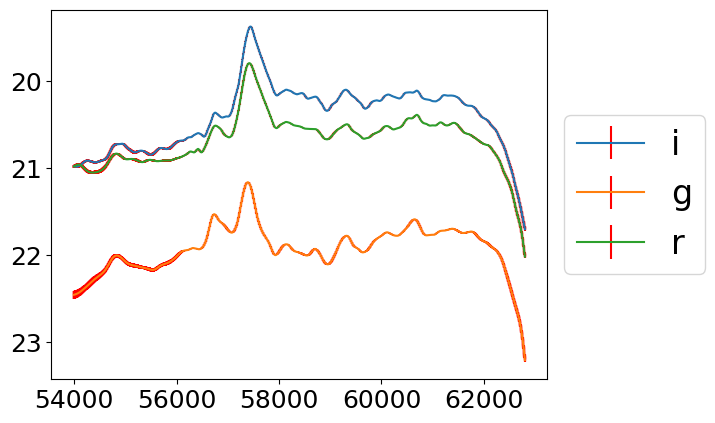

In [52]:
plt.errorbar(t_ran, i_new, i_new_err, ecolor='r', label='i')
plt.errorbar(t_ran, g_new, g_new_err, ecolor='r', label='g')
plt.errorbar(t_ran, r_new, r_new_err, ecolor='r', label='r')

plt.gca().invert_yaxis()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [53]:
g_new_dered, r_new_dered, i_new_dered, z_new_dered = g_new - A["g"], r_new - A["r"], i_new - A["i"], z_new - A["z"]


Text(0, 0.5, 'mag')

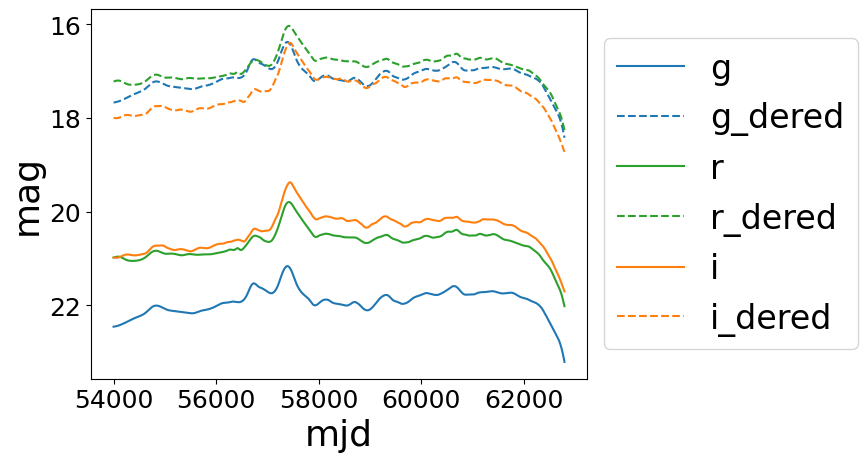

In [54]:

plt.plot(t_ran, g_new, '-', c=plt.cm.tab10(0), label='g')
plt.plot(t_ran, g_new_dered, '--', c=plt.cm.tab10(0), label='g_dered')

plt.plot(t_ran, r_new, '-', c=plt.cm.tab10(2), label='r')
plt.plot(t_ran, r_new_dered, '--', c=plt.cm.tab10(2), label='r_dered')

plt.plot(t_ran, i_new, '-', c=plt.cm.tab10(1), label='i')
plt.plot(t_ran, i_new_dered, '--', c=plt.cm.tab10(1), label='i_dered')


plt.gca().invert_yaxis()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel('mjd')
plt.ylabel('mag')



In [55]:
gi_dered = g_new_dered - i_new_dered
gi_new = g_new-i_new
teff_gi = teff_from_gi(gi_dered, tgrid, gi0)



In [56]:
gr_dered = g_new_dered - r_new_dered
gr_new = g_new-r_new
teff_gr = teff_from_gi(gr_dered, tgrid, gr0)


In [57]:
gi_dered

array([-0.32981596, -0.3301092 , -0.33040213, ..., -0.30660741,
       -0.30380076, -0.30098197])

In [58]:
gi_new

array([1.47833794, 1.4780447 , 1.47775177, ..., 1.50154649, 1.50435314,
       1.50717193])

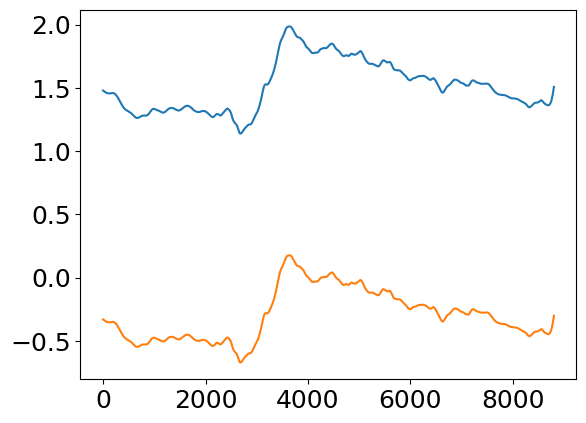

In [59]:
plt.plot(gi_new)
plt.plot(gi_dered)



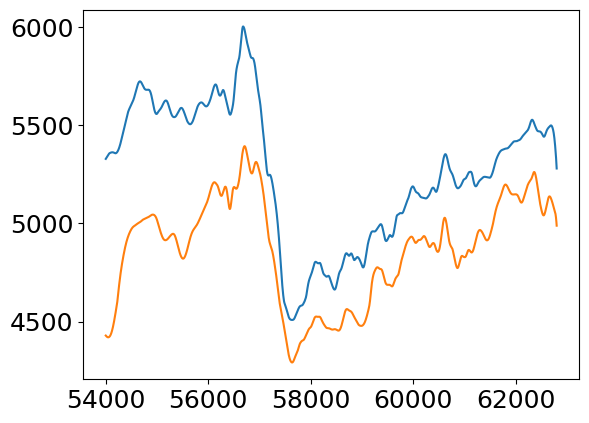

In [60]:
plt.plot(t_ran, teff_gi)
plt.plot(t_ran, teff_gr)

#plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
#
#plt.xlabel('mjd')
#plt.ylabel('T(K)')
#
#plt.axvline( 54850, color='k', ls='--', alpha=0.5)
#plt.axvline( 56740, color='k', ls='--', alpha=0.5)
#plt.axvline( 57430, color='k', ls='--', alpha=0.5)
#plt.axvline( 59300, color='k', ls='--', alpha=0.5)


### proposal plot

In [61]:
from LC_utility import *
from pdastro import *

In [ ]:
plt.rcParams['axes.labelsize'] =  26     # size of x/y labels
plt.rcParams['xtick.labelsize'] = 18   # size of tick labels
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 24

In [62]:
### historical LC
eta_historic = pdastrostatsclass()
eta_historic.load('./eta_full_revisedLC.txt', header=None, namesMapping={0:'Author',1:'Year',2:'Mag',3:'Mag_err'})

lc_flux_counts = 10 ** (-0.4 * (eta_historic.t['Mag']))
lc_flux_err = 0.921 * lc_flux_counts * eta_historic.t['Mag_err']
lc_mjd = Time(eta_historic.t['Year'].values, format='decimalyear', scale='utc').mjd + 57339 + 5068

eta_historic.t['Flux'] = lc_flux_counts
eta_historic.t['Flux_err'] = lc_flux_err
eta_historic.t['MJD'] = lc_mjd

/Users/home/Documents/EtaCarEchoes/old_vers1/pdastro.py:204: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  self.t = pd.read_table(filename,delim_whitespace=delim_whitespace,**kwargs)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 520 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 520 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 520 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


(1836.1, 1865.6)

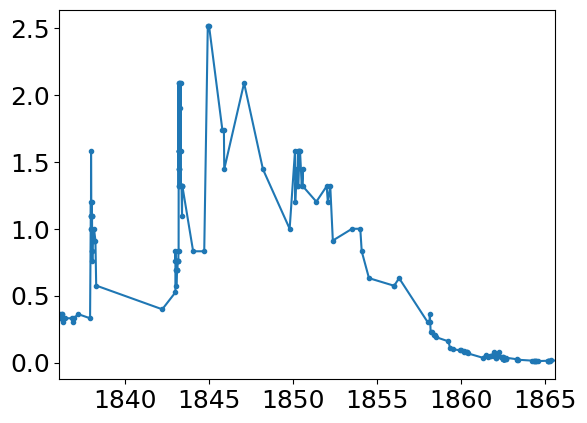

In [63]:
x = eta_historic.t['Year']
y = eta_historic.t['Flux']

y_err = eta_historic.t['Flux_err']
plt.plot(x, y, '.-')

plt.xlim(1836.1, 1865.6)


In [65]:
LCm2_g

,mjd,muJyas2,muJyas2_err,phase,AB_mag,AB_mag_err
0,53044.369999,5.242366,0.267675,-4399.911707,22.101182,0.055451
1,53046.889893,5.236889,0.262847,-4397.391812,22.102317,0.054508
2,53049.409788,5.231404,0.258084,-4394.871917,22.103454,0.053576
3,53051.929683,5.225910,0.253389,-4392.352022,22.104595,0.052657
4,53054.449578,5.220409,0.248762,-4389.832127,22.105739,0.051750
...,...,...,...,...,...,...
4995,65631.244631,-0.046727,0.085816,8186.962926,NaN,NaN
4996,65633.764526,-0.042025,0.088912,8189.482821,NaN,NaN
4997,65636.284421,-0.037322,0.092125,8192.002715,NaN,NaN
4998,65638.804315,-0.032621,0.095450,8194.522610,NaN,NaN


In [70]:
from astropy.time import Time
#t_ran_year = Time(t_ran, format='mjd', scale='utc').decimalyear

Text(0, 0.5, 'flux')

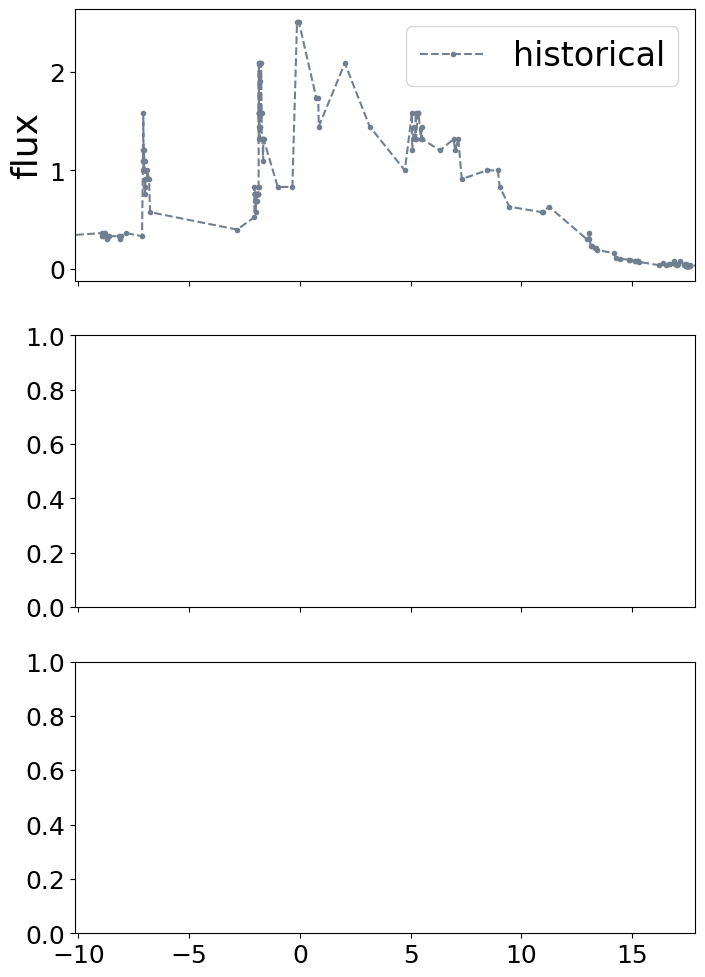

In [93]:
def phase_to_historic_year(x):
    return 1845 + x

def historic_year_to_phase(x):
    return x-1845




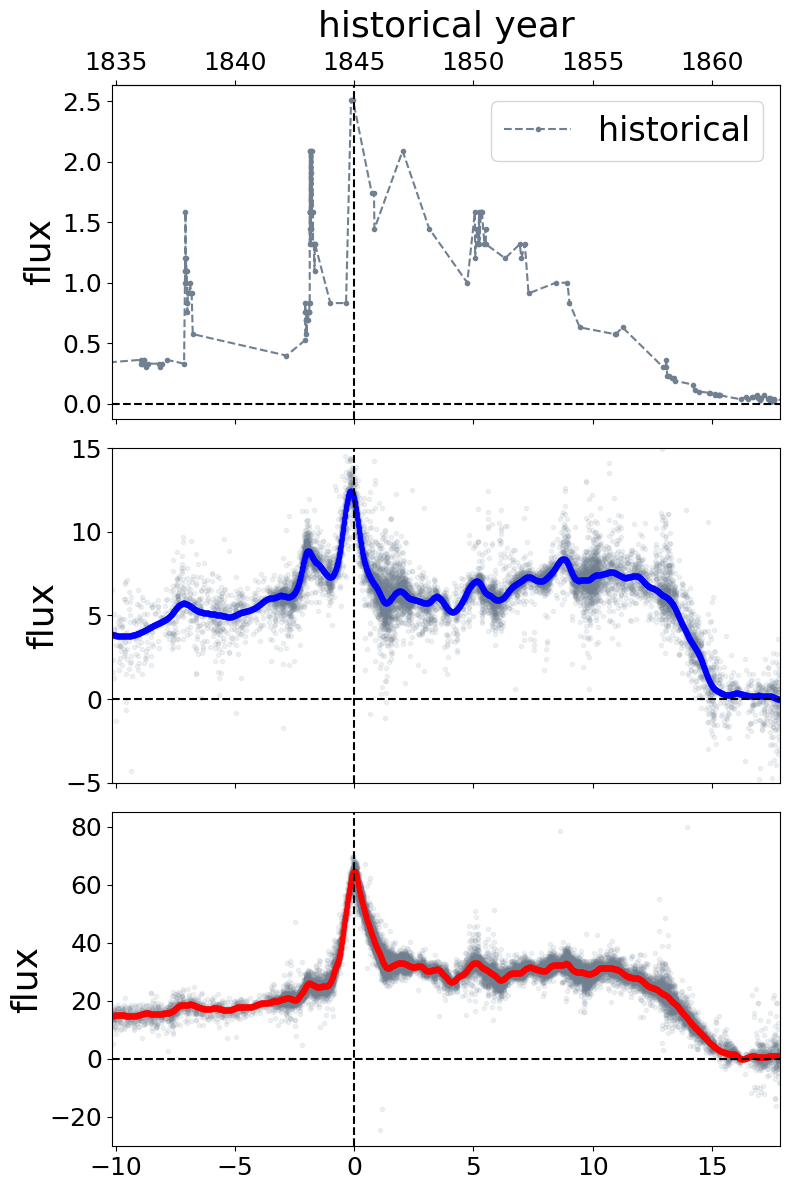

In [94]:

fig, axs = plt.subplots(3, 1, figsize=(8, 12), sharex=True)

ax = axs[0]

peak_t = 2016.15

x = eta_historic.t['Year'] + 171.1 - peak_t
y = eta_historic.t['Flux']

y_err = eta_historic.t['Flux_err']
ax.plot(x, y, '.--', color='slategray', label='historical')
ax.set_xlim(2006-peak_t, 2034-peak_t)



ax.legend()
ax.set_ylabel('flux')


ax_top = ax.secondary_xaxis(
    'top',
    functions=(phase_to_historic_year, historic_year_to_phase)
)
ax_top.set_xlabel("historical year", labelpad=10);
ax_top.set_xticks([1835, 1840, 1845, 1850, 1855, 1860]);



# ----------------

ax = axs[1]

LCdat2_g['year'] = Time(LCdat2_g['mjd'], format='mjd', scale='utc').decimalyear - peak_t

df = LCdat2_g
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.1, color='slategray' )


LCm2_g['year'] = Time(LCm2_g['mjd'], format='mjd', scale='utc').decimalyear - peak_t


df = LCm2_g
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.5, color='b')

ax.set_ylabel('flux')
ax.set_ylim([-5, 15])
# ----------------

ax = axs[2]

LCdat2_i['year'] = Time(LCdat2_i['mjd'], format='mjd', scale='utc').decimalyear - peak_t

df = LCdat2_i
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.1, color='slategray' )


LCm2_i['year'] = Time(LCm2_i['mjd'], format='mjd', scale='utc').decimalyear - peak_t


df = LCm2_i
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.5, color='r')

ax.set_ylabel('flux')
# ----------------

for ax in axs:
    ax.axhline(y=0, ls='--', c='k')
    ax.axvline(x=0, ls='--', c='k')

fig.tight_layout()

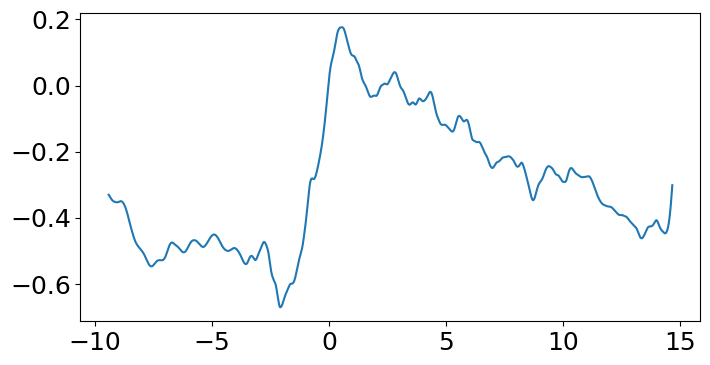

In [98]:
plt.figure(figsize=(8, 4))

t_ran_year = Time(t_ran, format='mjd', scale='utc').decimalyear

plt.plot(t_ran_year - peak_t, g_new_dered - i_new_dered)




Charlie

In [ ]:
    filters = ps.load_filters()
    teffs, _, wave, flux = ps.template_library(filters)
    tgrid, gi0 = pickles_gi_calibration(filters, teffs, wave, flux)

    A = band_extinctions(filters, teffs, wave, flux, EBV, RV)
    A_hi = band_extinctions(filters, teffs, wave, flux, EBV + EBV_ERR, RV)
    A_lo = band_extinctions(filters, teffs, wave, flux, EBV - EBV_ERR, RV)
    e_gi = (A["g"] - A["i"])
    de_gi = 0.5 * abs((A_hi["g"] - A_hi["i"]) - (A_lo["g"] - A_lo["i"]))

    t, g, ge, r, re, i, ie, z, ze = load_light_curves()
    g0, r0, i0, z0 = g - A["g"], r - A["r"], i - A["i"], z - A["z"]

    gi = g0 - i0
    gr = g0 - r0
    ri = r0 - i0
    iz = i0 - z0
    gi_err_phot = np.sqrt(ge**2 + ie**2)
    gi_err = np.sqrt(gi_err_phot**2 + de_gi**2 + GI_SYS**2)
    gr_err = np.sqrt(ge**2 + re**2 + GI_SYS**2)
    ri_err = np.sqrt(re**2 + ie**2)
    iz_err = np.sqrt(ie**2 + ze**2)

    teff = teff_from_gi(gi, tgrid, gi0)
    teff_lo = teff_from_gi(gi + gi_err, tgrid, gi0)  # redder → cooler
    teff_hi = teff_from_gi(gi - gi_err, tgrid, gi0)
